# Parameters

There are 2 sets of parameters:
1. Extrinsic – 6 degrees of freedom (DOF)
    1. Translation - 3 DOF (x, y, z)
    2. Rotation – 3 DOF (roll, pitch, yaw)
2. Intrinsic – 5 DOF
    1. Ratio – in general, pixels might be not square (in modern cameras they are usually square, and opencv has this assumption of square pixels), so while we mape the real world to pixel coordinates, we use 2 parameters (alpha, beta) – 2 DOF
    2. Optical center – it might not correspond to the image center – 2 DOF
    3. Skew - axes might not be perpendicular, and we want to know the real angle – 1 DOF

# Extrinsic transformations
## Translation
<img src="2_images/translation.png" width="750">

## Rotation
Formula for rotation

<img src="2_images/rotation_general.png" width="750">

Matrix _R_ has a form:

<img src="2_images/rotation_matrix.png" width="1000">

Note 1: columns are axes of frame A expressed in frame B; rows are axes of frame B expressed in frame A.

Note 2: inversed and transposed matrices _R_ are equal.

Rotation around Z axis:

<img src="2_images/rotation_around_z.png" width="750">

Rotation could be represented as 3 consecutive rotations around single axis, and the order of these rotations matter.
Examples of possible approaches:

<img src="2_images/rotation_representations.png" width="750">

<img src="2_images/rotation_homogeneous.png" width="1000">

## Rigid transformation

Combining a matrix form of translation and rotation we get:

<img src="2_images/rigid_transformation.png" width="750">

4*4 matrices in homogeneous coordinates are, typically, invertible.
It allows us to write inverse transformation:

<img src="2_images/rigid_inverse.png" width="750">
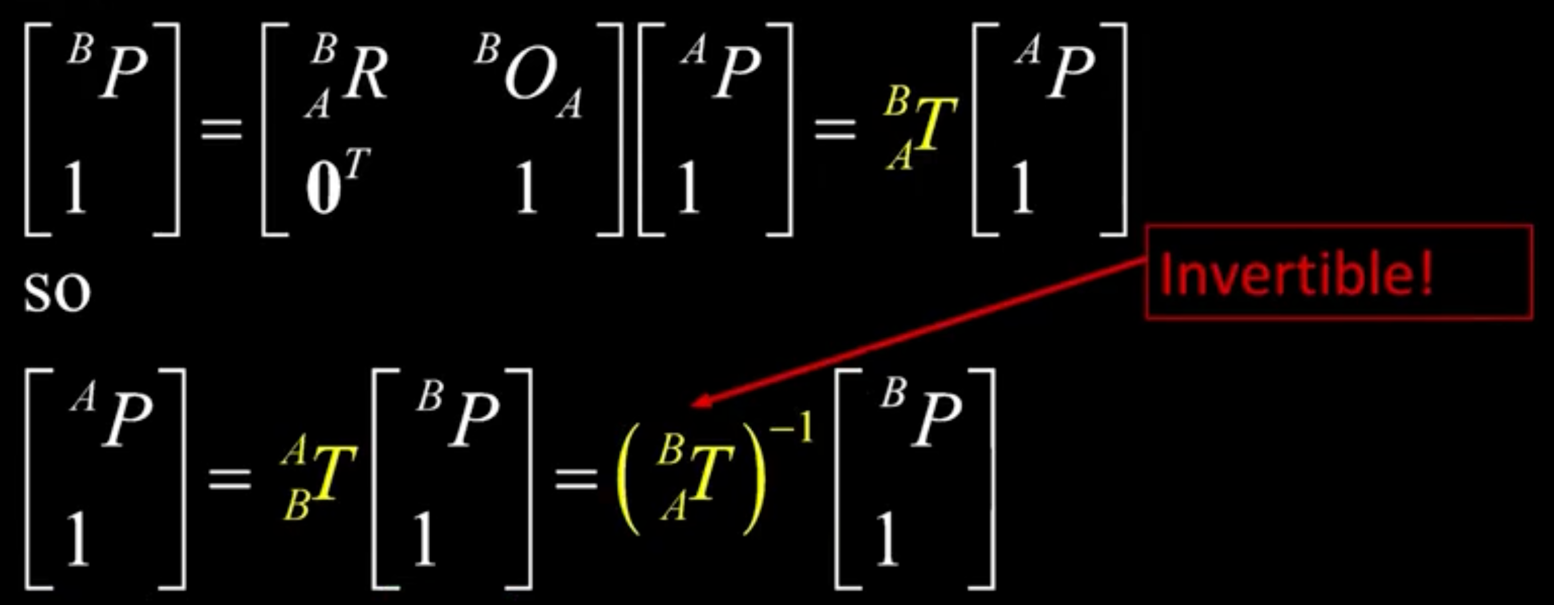

# Intrinsic transformations
Ideal perspective projection:

<img src="2_images/pp_ideal.png" width="750">

But in the real world, there are several distortions we need to address:

## Pixel units

Focal length and pixels are in different measurement units, so we need to use unit-independent scale factor:

<img src="2_images/pp_units.png" width="750">

## Ratio

But pixels might not be square, so we need to use 2 different factors:

<img src="2_images/pp_ratio.png" width="750">

## Optical center

The optical center of the camera might not correspond to the center of the image:

<img src="2_images/pp_optical_center.png" width="750">

## Skew

Axes might not be perpendicular:

<img src="2_images/pp_skew.png" width="750">


## Final Form

If we put together all formulas, we get:

<img src="2_images/pp_final.png" width="750">

It looks much better if we move to the matrix form and homogeneous coordinates:

<img src="2_images/pp_final_homogeneous.png" width="500">

Or simpler, if we remove the last column of 0s:

<img src="2_images/pp_final_homogeneous_short.png" width="500">

If we assume that pixels are square, the optical center is in the middle of the image, and there is no skew, the matrix has only 1 DOF:

<img src="2_images/pp_final_ideal.png" width="500">

# Camera calibration transformation

If we put together extrinsic and intrinsic parameters we get:

<img src="2_images/camera_calibration.png" width="1000">

# Camera calibration parameters estimation

In homogeneous coordinates, the representation of transformation matrix M could be simplified and viewed as a 3x4 matrix.
As a result, is we have a set of points in the real world and their corresponding projections in pixels,
we came up with a homogeneous system of linear algebraic equations:

<img src="2_images/cc_slae.png" width="750">

Note: matrix M is scale independent as scale will be reduced on conversion from homogeneous coordinates.

Note: the more equations we have - the better. We need at least 6 points (12>11 equations)

As a result, we can solve this problem for unit vector m* ($\lVert m* \rVert$=1).
It could be viewed as the least squares problem – minimize $\lVert Am \rVert$

The solution of this task is - **Vector m* = eigenvector of A$^T$A* with the smallest eigenvalue.

## Explanation
https://www.youtube.com/watch?v=8i10fg_0Cc8

https://www.youtube.com/watch?v=WZ6Ipfzdyck

<img src="2_images/svd_trick_1.png" width="1000">
<img src="2_images/svd_trick_2.png" width="1000">
<img src="2_images/svd_trick_3.png" width="1000">
<img src="2_images/svd_trick_4.png" width="1000">

# Errors accounting

The previous model does not take into account such errors as radial distortion, lens distortion, and other factors.
For this reason, the geometric error minimization is used afterward (it minimizes projection error of points on the image plane):

<img src="2_images/camera_calibration_final.png" width="1000">

# Camera center form matrix

M - transformation matrix (3 x 4)

$M = [Q | b]$ – where Q is a 3x3 matrix and b is a 3x1 vector (last column of M).

$C = \begin{pmatrix} -Q^-1 \\ 1 \end{pmatrix}$ - camera center